# MLP Inference using optimal parameters

In [3]:
import sys
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Add parent directory to path to access the src module
sys.path.append(os.path.abspath('..')) 

from src.data_loader import load_svhn_data
from src.features import extract_flattened, extract_pca, extract_resnet_embeddings
from src.pytorch_mlp import MLPClassifier
from sklearn.model_selection import train_test_split

# 1. Load SVHN Dataset
print("--- Loading SVHN Dataset ---")
X_train_raw, y_train, X_test_raw, y_test = load_svhn_data(
    data_dir="../data/raw", 
    normalize=True,
    balanced=False  # We do not want balanced subset
)

# 2. Extract Features
print("\n--- Extracting Flattened Features ---")
X_train_flat, X_test_flat = extract_flattened(X_train_raw, X_test_raw, standardize=True)

print("--- Extracting PCA Features (53 comp.) ---")
X_train_pca, X_test_pca, _ = extract_pca(X_train_flat, X_test_flat, n_components=53, random_state=42)

# Create Validation Set
X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(
    X_train_pca, y_train, 
    test_size=5000, 
    stratify=y_train, 
    random_state=42
)

print(f"Training dimensions: {X_train_final.shape}")
print(f"Validation dimensions: {X_val_final.shape}")
print(f"Test dimensions: {X_test_pca.shape}")

--- Loading SVHN Dataset ---
Loading SVHN Dataset
Dataset Loaded. Train: (73257, 3, 32, 32), Test: (26032, 3, 32, 32)

--- Extracting Flattened Features ---
--- Extracting PCA Features (53 comp.) ---
Training dimensions: (68257, 53)
Validation dimensions: (5000, 53)
Test dimensions: (26032, 53)


## MLP Training

In [4]:
print("Training Optimal MLP...")
print("-" * 75)

optimal_mlp = MLPClassifier(
    hidden_layers=[256, 128, 64],  
    activation='relu',
    learning_rate=0.01,
    weight_decay=0.001,
    epochs=60,                     
    T_0=15,
    batch_size=64,
    random_state=42,
    use_class_weights=True,       
    verbose=1                     
)

t0 = time.time()
    
# Training
optimal_mlp.fit(X_train_final, y_train_final, X_val=X_val_final, y_val=y_val_final)
print(f"\nTraining finished in {time.time() - t0:.2f} seconds.")   

Training Optimal MLP...
---------------------------------------------------------------------------
Using Class Weights: [1.4806 0.5285 0.6921 0.8622 0.9823 1.0645 1.2792 1.3094 1.452  1.5724]
Epoch 01/60 | LR: 0.009891 | Train Loss: 1.3801 | Val F1: 0.6462
Epoch 02/60 | LR: 0.009568 | Train Loss: 1.0861 | Val F1: 0.6447
Epoch 03/60 | LR: 0.009045 | Train Loss: 1.0083 | Val F1: 0.6575
Epoch 04/60 | LR: 0.008346 | Train Loss: 0.9617 | Val F1: 0.6990
Epoch 05/60 | LR: 0.007500 | Train Loss: 0.9199 | Val F1: 0.7216
Epoch 06/60 | LR: 0.006545 | Train Loss: 0.8793 | Val F1: 0.7244
Epoch 07/60 | LR: 0.005523 | Train Loss: 0.8368 | Val F1: 0.7270
Epoch 08/60 | LR: 0.004477 | Train Loss: 0.7959 | Val F1: 0.7458
Epoch 09/60 | LR: 0.003455 | Train Loss: 0.7504 | Val F1: 0.7634
Epoch 10/60 | LR: 0.002500 | Train Loss: 0.7049 | Val F1: 0.7637
Epoch 11/60 | LR: 0.001654 | Train Loss: 0.6607 | Val F1: 0.7892
Epoch 12/60 | LR: 0.000955 | Train Loss: 0.6158 | Val F1: 0.7971
Epoch 13/60 | LR: 0.000432 

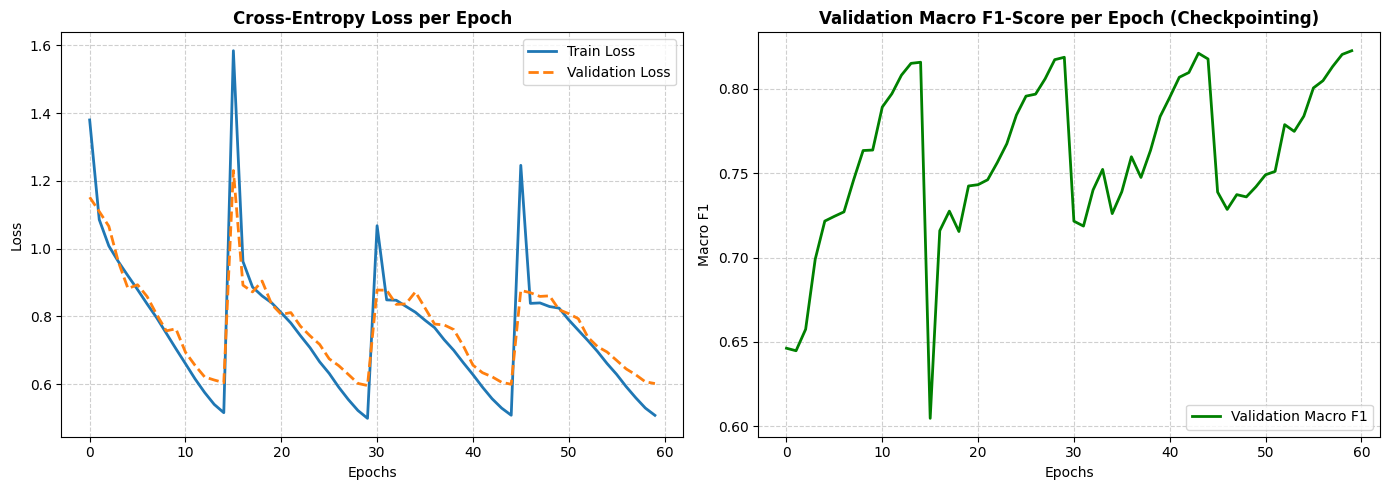

In [5]:
history = optimal_mlp.history_

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history['train_loss'], label='Train Loss', color='#1f77b4', linewidth=2)
ax1.plot(history['val_loss'], label='Validation Loss', color='#ff7f0e', linewidth=2, linestyle='--')
ax1.set_title('Cross-Entropy Loss per Epoch', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(history['val_macro_f1'], label='Validation Macro F1', color='green', linewidth=2)
ax2.set_title('Validation Macro F1-Score per Epoch (Checkpointing)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Macro F1')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

--- Evaluating on Official Test Set ---
FINAL TEST MACRO F1-SCORE: 0.7959



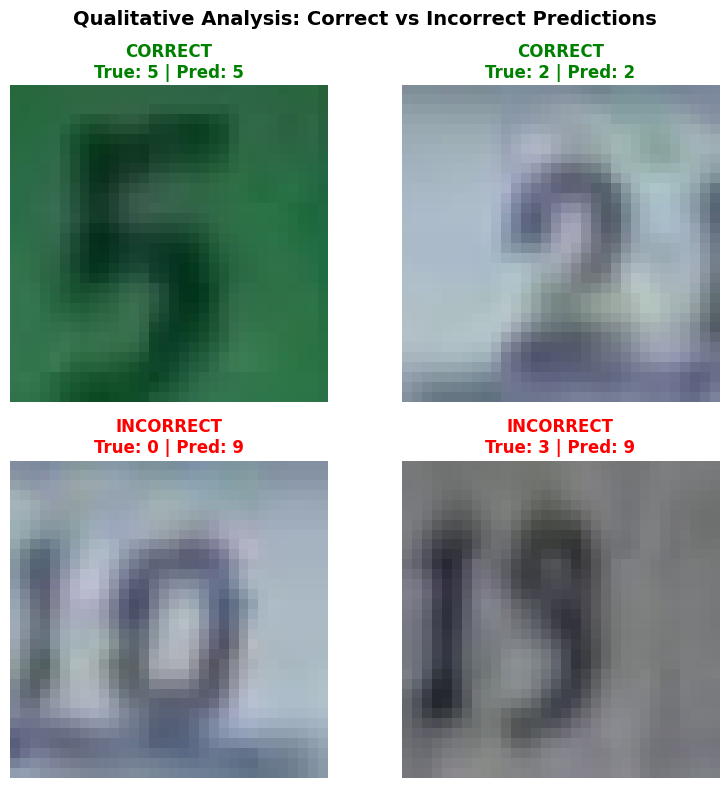

In [6]:
print("--- Evaluating on Official Test Set ---")
y_pred = optimal_mlp.predict(X_test_pca)

test_f1 = f1_score(y_test, y_pred, average='macro')
print(f"FINAL TEST MACRO F1-SCORE: {test_f1:.4f}\n")

correct_indices = np.where(y_pred == y_test)[0][:2]
wrong_indices = np.where(y_pred != y_test)[0][:2]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))


for i, idx in enumerate(correct_indices):
   
    img = np.transpose(X_test_raw[idx], (1, 2, 0)) 
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"CORRECT\nTrue: {y_test[idx]} | Pred: {y_pred[idx]}", color="green", fontweight='bold')
    axes[0, i].axis("off")


for i, idx in enumerate(wrong_indices):
    img = np.transpose(X_test_raw[idx], (1, 2, 0))
    axes[1, i].imshow(img)
    axes[1, i].set_title(f"INCORRECT\nTrue: {y_test[idx]} | Pred: {y_pred[idx]}", color="red", fontweight='bold')
    axes[1, i].axis("off")

plt.suptitle("Qualitative Analysis: Correct vs Incorrect Predictions", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()